# Project name:-Predictive Maintenance & Remaining Useful Life (RUL) Prediction
#### 1 Problem statement:- To develop a machine learning model that analyzes engine sensor data to predict the Remaining Useful Life (RUL) of aircraft turbofan engines. The goal is to support proactive maintenance, reduce unexpected failures, and improve equipment reliability.
#### 2 Dataset Collection:
####  Dataset link:- 
https://catalog.data.gov/dataset/cmapss-jet-engine-simulated-data?utm_source=chatgpt.com

# Import Data and required package 


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/raw/train_FD001.txt", sep=r"\s+", header=None)


In [3]:
df.head()

,0,1,2,3,4,5,6,7,8,9,...,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
# Give the name of every coloum
columns = [
    "unit", "cycle",
    "setting_1", "setting_2", "setting_3",
    "sensor_1", "sensor_2", "sensor_3", "sensor_4", "sensor_5",
    "sensor_6", "sensor_7", "sensor_8", "sensor_9", "sensor_10",
    "sensor_11", "sensor_12", "sensor_13", "sensor_14", "sensor_15",
    "sensor_16", "sensor_17", "sensor_18", "sensor_19", "sensor_20",
    "sensor_21"
]

df.columns = columns



In [5]:
df.head()

,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [6]:
# Cheacking the datatypes
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   unit       20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-null  float64
 6   sensor_2   20631 non-null  float64
 7   sensor_3   20631 non-null  float64
 8   sensor_4   20631 non-null  float64
 9   sensor_5   20631 non-null  float64
 10  sensor_6   20631 non-null  float64
 11  sensor_7   20631 non-null  float64
 12  sensor_8   20631 non-null  float64
 13  sensor_9   20631 non-null  float64
 14  sensor_10  20631 non-null  float64
 15  sensor_11  20631 non-null  float64
 16  sensor_12  20631 non-null  float64
 17  sensor_13  20631 non-null  float64
 18  sensor_14  20631 non-null  float64
 19  sensor_15  20631 non-null  float64
 20  sensor

In [7]:
# To cheak any missing value:- There is no any missing value
df.isnull().sum()

unit         0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
unit,20631.0,51.506568,2.922763e+01,1.0000,26.0000,52.0000,77.0000,100.0000
cycle,20631.0,108.807862,6.888099e+01,1.0000,52.0000,104.0000,156.0000,362.0000
setting_1,20631.0,-0.000009,2.187313e-03,-0.0087,-0.0015,0.0000,0.0015,0.0087
setting_2,20631.0,0.000002,2.930621e-04,-0.0006,-0.0002,0.0000,0.0003,0.0006
setting_3,20631.0,100.000000,0.000000e+00,100.0000,100.0000,100.0000,100.0000,100.0000
sensor_1,20631.0,518.670000,6.537152e-11,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0,642.680934,5.000533e-01,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0,1590.523119,6.131150e+00,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0,1408.933782,9.000605e+00,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0,14.620000,3.394700e-12,14.6200,14.6200,14.6200,14.6200,14.6200


In [9]:
df.nunique()

unit          100
cycle         362
setting_1     158
setting_2      13
setting_3       1
sensor_1        1
sensor_2      310
sensor_3     3012
sensor_4     4051
sensor_5        1
sensor_6        2
sensor_7      513
sensor_8       53
sensor_9     6403
sensor_10       1
sensor_11     159
sensor_12     427
sensor_13      56
sensor_14    6078
sensor_15    1918
sensor_16       1
sensor_17      13
sensor_18       1
sensor_19       1
sensor_20     120
sensor_21    4745
dtype: int64

In [10]:
df.std()[df.std() < 0.01]

setting_1    2.187313e-03
setting_2    2.930621e-04
setting_3    0.000000e+00
sensor_1     6.537152e-11
sensor_5     3.394700e-12
sensor_6     1.388985e-03
sensor_10    4.660829e-13
sensor_16    1.556432e-14
sensor_18    0.000000e+00
sensor_19    0.000000e+00
dtype: float64

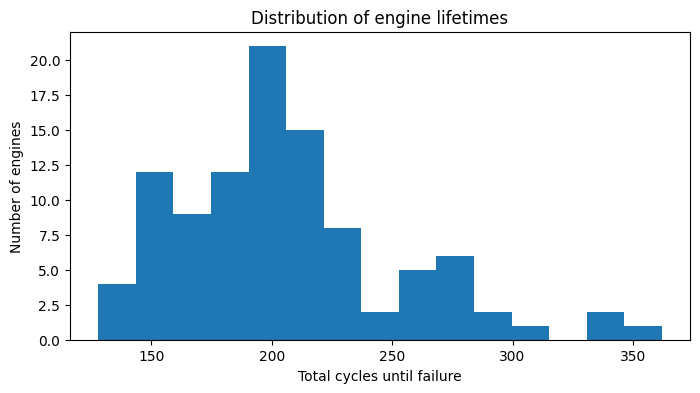

In [11]:
# Distribuation analysis
life = df.groupby("unit")["cycle"].max()

plt.figure(figsize=(8, 4))
plt.hist(life, bins=15)
plt.title("Distribution of engine lifetimes")
plt.xlabel("Total cycles until failure")
plt.ylabel("Number of engines")
plt.show()

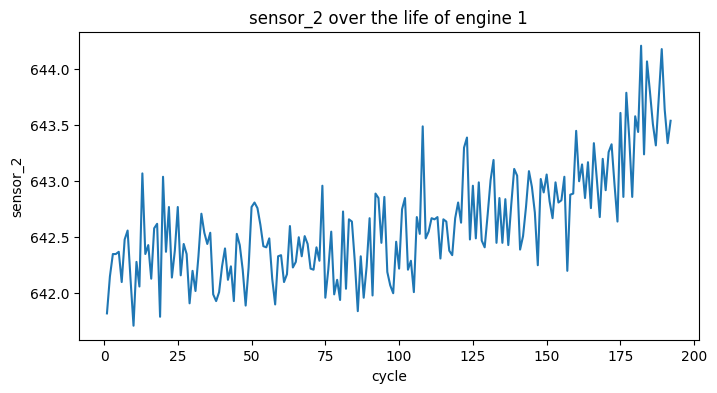

In [12]:
# Trend of sensor
engine = df[df["unit"] == 1]

plt.figure(figsize=(8, 4))
plt.plot(engine["cycle"], engine["sensor_2"])
plt.xlabel("cycle")
plt.ylabel("sensor_2")
plt.title("sensor_2 over the life of engine 1")
plt.show()

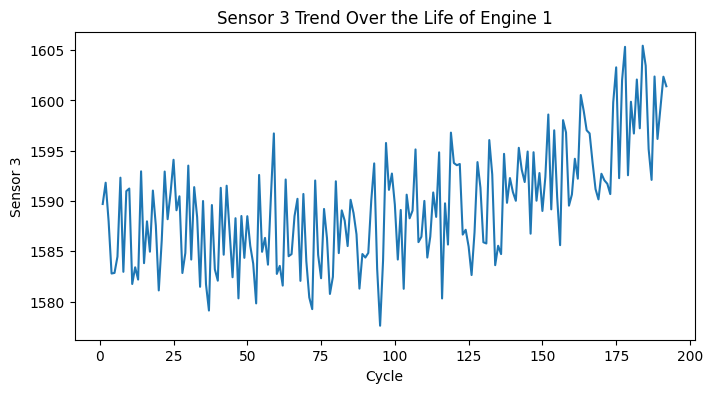

In [13]:
# I cheak the sensor 3 Trend over the life of engine1

engine = df[df["unit"] == 1]
plt.figure(figsize=(8, 4))
plt.plot(engine["cycle"], engine["sensor_3"])
plt.xlabel("Cycle")
plt.ylabel("Sensor 3")
plt.title("Sensor 3 Trend Over the Life of Engine 1")
plt.show()

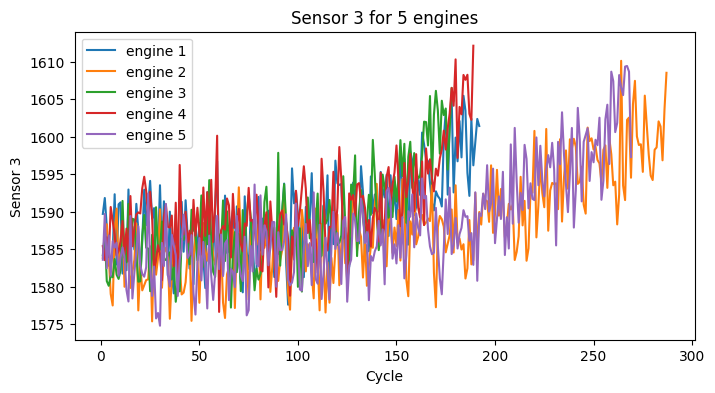

In [14]:
# 
plt.figure(figsize=(8, 4))

for u in [1, 2, 3, 4, 5]:
    e = df[df["unit"] == u]
    plt.plot(e["cycle"], e["sensor_3"], label=f"engine {u}")

plt.xlabel("Cycle")
plt.ylabel("Sensor 3")
plt.title("Sensor 3 for 5 engines")
plt.legend()
plt.show()

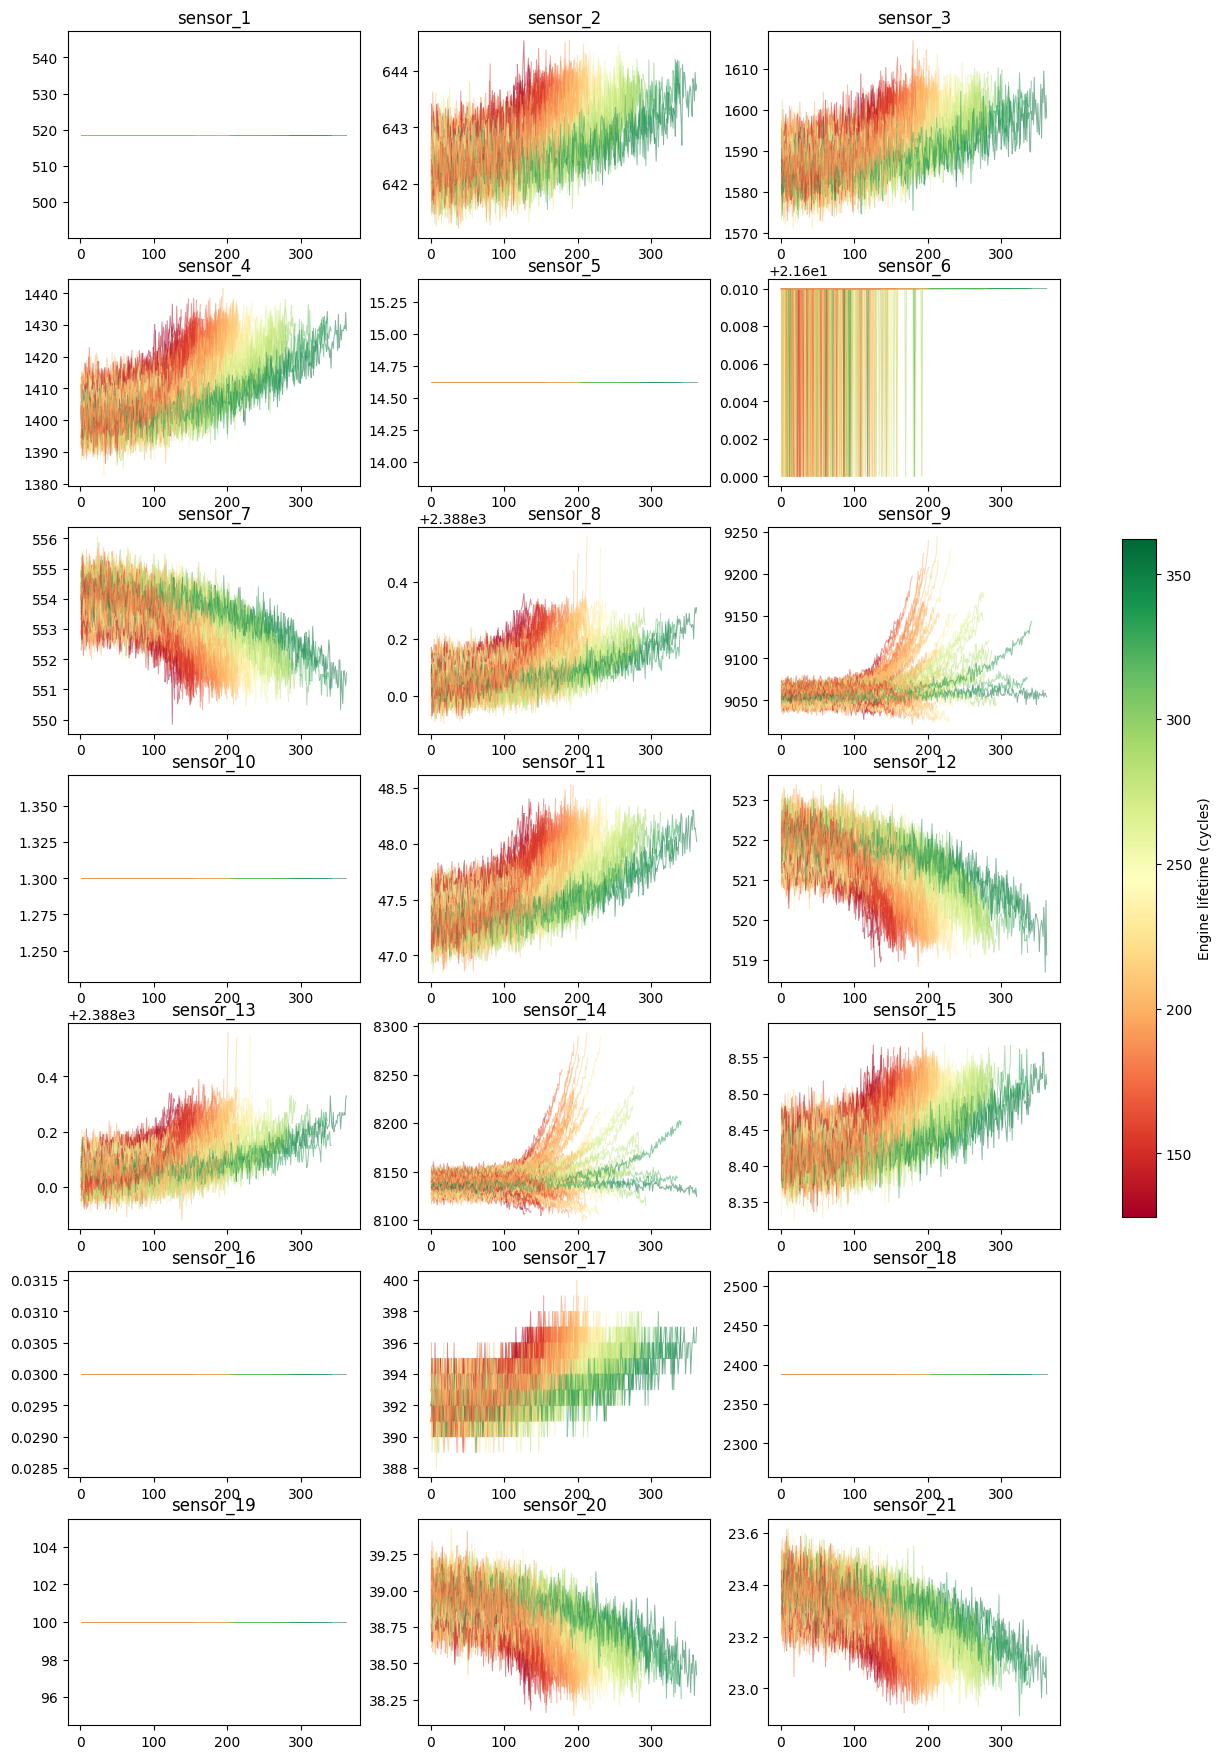

In [ ]:
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]

life = df.groupby("unit")["cycle"].max()
norm = plt.Normalize(life.min(), life.max())
cmap = plt.cm.RdYlGn

fig, axes = plt.subplots(7, 3, figsize=(16, 22))
axes = axes.flatten()

for i, col in enumerate(sensor_cols):
    for u, g in df.groupby("unit"):
        axes[i].plot(g["cycle"], g[col], color=cmap(norm(life[u])), alpha=0.5, linewidth=0.7)
    axes[i].set_title(col)

fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes.tolist(),
             shrink=0.4, label="Engine lifetime (cycles)")
plt.show()

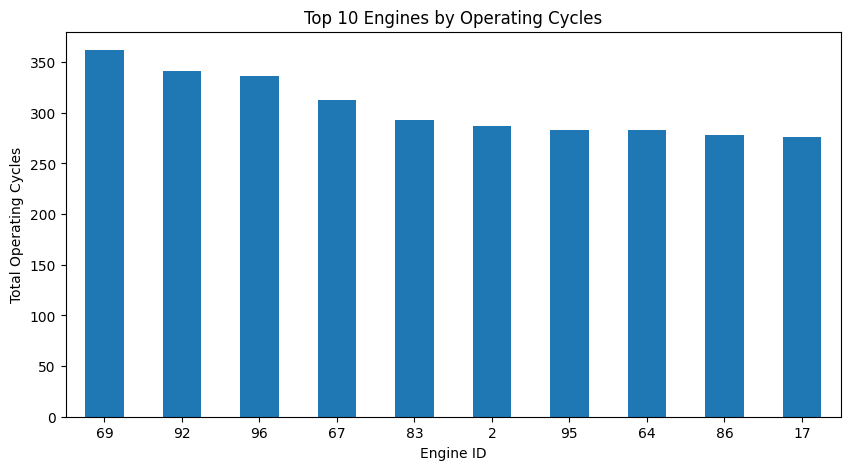

In [18]:
# Find the maximum operating cycle for each engine
engine_cycles = df.groupby("unit")["cycle"].max()

# Select the 10 engines with the most operating cycles
top_10_engines = engine_cycles.sort_values(ascending=False).head(10)

# Plot the results
plt.figure(figsize=(10, 5))
top_10_engines.plot(kind="bar")

plt.xlabel("Engine ID")
plt.ylabel("Total Operating Cycles")
plt.title("Top 10 Engines by Operating Cycles")
plt.xticks(rotation=0)
plt.show()

In [ ]:

# Cheaking the duplicated value are presentor not 
df.duplicated().sum()

np.int64(0)

In [ ]:
# Sensor Correlation Analysis with Remaining Useful Life (RUL)
rul = df.groupby("unit")["cycle"].transform("max") - df["cycle"]

df.drop(columns="unit").corrwith(rul).sort_values()

c:\Users\lenovo\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3065: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
c:\Users\lenovo\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3066: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


cycle       -7.362406e-01
sensor_11   -6.962281e-01
sensor_4    -6.789482e-01
sensor_15   -6.426670e-01
sensor_2    -6.064840e-01
sensor_17   -6.061536e-01
sensor_3    -5.845204e-01
sensor_8    -5.639684e-01
sensor_13   -5.625688e-01
sensor_9    -3.901016e-01
sensor_14   -3.067689e-01
sensor_6    -1.283484e-01
setting_1   -3.198458e-03
setting_2   -1.947628e-03
sensor_16   -6.041754e-16
sensor_5     1.299660e-15
sensor_20    6.294285e-01
sensor_21    6.356620e-01
sensor_7     6.572227e-01
sensor_12    6.719831e-01
setting_3             NaN
sensor_1              NaN
sensor_10             NaN
sensor_18             NaN
sensor_19             NaN
dtype: float64